In [1]:
#read in gene vs disease data
import pandas as pd
import scipy as sp
import numpy as np
from lightfm import cross_validation
from lightfm.evaluation import precision_at_k
from lightfm.evaluation import recall_at_k
from lightfm.evaluation import auc_score
from lightfm import LightFM
import matplotlib.pyplot as plt
import pickle

tsv_file = open("curated_gene_disease_associations.tsv")
df = pd.read_csv(tsv_file, delimiter="\t")

In [2]:
df.head(15)

,geneId,geneSymbol,DSI,DPI,diseaseId,diseaseName,diseaseType,diseaseClass,diseaseSemanticType,score,EI,YearInitial,YearFinal,NofPmids,NofSnps,source
0,1,A1BG,0.700,0.538,C0019209,Hepatomegaly,phenotype,C23;C06,Finding,0.30,1.000,2017.0,2017.0,1,0,CTD_human
1,1,A1BG,0.700,0.538,C0036341,Schizophrenia,disease,F03,Mental or Behavioral Dysfunction,0.30,1.000,2015.0,2015.0,1,0,CTD_human
2,2,A2M,0.529,0.769,C0002395,Alzheimer's Disease,disease,C10;F03,Disease or Syndrome,0.50,0.769,1998.0,2018.0,3,0,CTD_human
3,2,A2M,0.529,0.769,C0007102,Malignant tumor of colon,disease,C06;C04,Neoplastic Process,0.31,1.000,2004.0,2019.0,1,0,CTD_human
4,2,A2M,0.529,0.769,C0009375,Colonic Neoplasms,group,C06;C04,Neoplastic Process,0.30,1.000,2004.0,2004.0,1,0,CTD_human
5,2,A2M,0.529,0.769,C0011265,Presenile dementia,disease,C10;F03,Mental or Behavioral Dysfunction,0.30,1.000,1998.0,2004.0,3,0,CTD_human
6,2,A2M,0.529,0.769,C0011570,Mental Depression,disease,F01,Mental or Behavioral Dysfunction,0.30,1.000,1987.0,2000.0,2,0,PSYGENET
7,2,A2M,0.529,0.769,C0011581,Depressive disorder,disease,F03,Mental or Behavioral Dysfunction,0.30,1.000,1987.0,2000.0,2,0,PSYGENET
8,2,A2M,0.529,0.769,C0019202,Hepatolenticular Degeneration,disease,C16;C06;C18;C10,Disease or Syndrome,0.30,1.000,2013.0,2013.0,1,0,CTD_human
9,2,A2M,0.529,0.769,C0022660,"Kidney Failure, Acute",disease,C13;C12,Disease or Syndrome,0.30,1.000,2013.0,2013.0,1,0,CTD_human


In [3]:
#creating df with gene, disease, and association score
gd_df = df[['geneId', 'diseaseId', 'score']]

In [4]:
#finding unique genes and diseases
geneId_values = np.unique(gd_df['geneId'].values)
diseaseId_values = np.unique(gd_df['diseaseId'].values)

In [5]:
#Creating sparse matrix from csv formatted data
gd_matrix = pd.DataFrame(index = diseaseId_values, columns = geneId_values)

for disease in diseaseId_values:
    disease_df = gd_df[gd_df['diseaseId']==disease].set_index('geneId')
    gd_matrix.loc[disease] = disease_df['score']
    
gd_np = gd_matrix.to_numpy()
gd_np = np.array(gd_np, dtype=float)
gd_np[np.isnan(gd_np)] = 0
gd_coo = sp.sparse.coo_matrix(gd_np)
print(gd_coo)

  (0, 1838)	0.3
  (1, 2388)	0.8
  (2, 96)	0.3
  (2, 723)	0.3
  (2, 740)	0.3
  (2, 1190)	0.35
  (2, 1310)	0.33
  (2, 1314)	0.31
  (2, 2554)	0.4
  (2, 3293)	0.35
  (2, 3411)	0.35
  (2, 4601)	0.3
  (2, 5235)	0.33
  (3, 233)	0.3
  (3, 476)	0.3
  (3, 1144)	0.3
  (3, 3974)	0.3
  (3, 6366)	0.3
  (4, 247)	0.3
  (4, 603)	0.3
  (4, 654)	0.3
  (4, 841)	0.4
  (4, 1271)	0.4
  (4, 1520)	0.3
  (4, 1571)	0.3
  :	:
  (11166, 429)	0.3
  (11167, 2367)	0.3
  (11167, 2368)	0.3
  (11168, 2925)	0.3
  (11169, 5465)	0.3
  (11170, 6995)	0.3
  (11171, 2342)	0.3
  (11172, 3526)	0.3
  (11173, 4541)	0.3
  (11173, 5244)	0.32
  (11173, 5406)	0.3
  (11173, 5749)	0.3
  (11174, 7819)	0.3
  (11175, 543)	0.3
  (11176, 5504)	0.3
  (11177, 2367)	0.3
  (11178, 1023)	0.3
  (11179, 1023)	0.3
  (11180, 291)	0.3
  (11180, 294)	0.3
  (11180, 295)	0.3
  (11180, 2367)	0.3
  (11180, 2368)	0.3
  (11180, 7390)	0.3
  (11180, 8117)	0.3


In [6]:
#rescaling data to a max value of 5 (similar to movie dataset)
gd_scaled = gd_coo * 5
print(gd_scaled)

  (0, 1838)	1.5
  (1, 2388)	4.0
  (2, 96)	1.5
  (2, 723)	1.5
  (2, 740)	1.5
  (2, 1190)	1.75
  (2, 1310)	1.6500000000000001
  (2, 1314)	1.55
  (2, 2554)	2.0
  (2, 3293)	1.75
  (2, 3411)	1.75
  (2, 4601)	1.5
  (2, 5235)	1.6500000000000001
  (3, 233)	1.5
  (3, 476)	1.5
  (3, 1144)	1.5
  (3, 3974)	1.5
  (3, 6366)	1.5
  (4, 247)	1.5
  (4, 603)	1.5
  (4, 654)	1.5
  (4, 841)	2.0
  (4, 1271)	2.0
  (4, 1520)	1.5
  (4, 1571)	1.5
  :	:
  (11166, 429)	1.5
  (11167, 2367)	1.5
  (11167, 2368)	1.5
  (11168, 2925)	1.5
  (11169, 5465)	1.5
  (11170, 6995)	1.5
  (11171, 2342)	1.5
  (11172, 3526)	1.5
  (11173, 4541)	1.5
  (11173, 5244)	1.6
  (11173, 5406)	1.5
  (11173, 5749)	1.5
  (11174, 7819)	1.5
  (11175, 543)	1.5
  (11176, 5504)	1.5
  (11177, 2367)	1.5
  (11178, 1023)	1.5
  (11179, 1023)	1.5
  (11180, 291)	1.5
  (11180, 294)	1.5
  (11180, 295)	1.5
  (11180, 2367)	1.5
  (11180, 2368)	1.5
  (11180, 7390)	1.5
  (11180, 8117)	1.5


In [7]:
#splitting data into train and test and storing in data with geneIds
(train, test) = cross_validation.random_train_test_split(gd_coo, test_percentage=0.2, random_state=None)
data = {'train': train, 'test': test, 'gene_ids' : geneId_values}

In [8]:
#splitting scaled data into train and test and storing in data with geneIds
(train, test) = cross_validation.random_train_test_split(gd_scaled, test_percentage=0.2, random_state=None)
data_scaled = {'train': train, 'test': test, 'gene_ids' : geneId_values}

In [9]:
#creating model
model = LightFM(loss='warp')

In [10]:
#creating model for scaled data
model_scaled = LightFM(loss='warp')

In [11]:
#training model
model.fit(data['train'], epochs=100, num_threads=2)

In [12]:
#training model with scaled data
model_scaled.fit(data_scaled['train'], epochs=100, num_threads=2)

In [13]:
# measure AUC score
auc = auc_score(model, data['test']).mean()
print(auc)

0.8328442


In [14]:
# measure AUC score
auc_scaled = auc_score(model_scaled, data_scaled['test']).mean()
print(auc_scaled)

0.8336558


In [15]:
# measure precision/recall @ k for k=1:50
test_precision = []
test_recall = []
train_precision = []
train_recall = []

for i in range(1, 51):
    test_precision.append(precision_at_k(model, data['test'], k=i).mean())
    test_recall.append(recall_at_k(model, data['test'], k=i).mean())
    train_precision.append(precision_at_k(model, data['train'], k=i).mean())
    train_recall.append(recall_at_k(model, data['train'], k=i).mean())
    if i % 5 == 0:
        print('k = %s done' %(i))

k = 5 done
k = 10 done
k = 15 done
k = 20 done
k = 25 done
k = 30 done
k = 35 done
k = 40 done
k = 45 done
k = 50 done


In [17]:
# measure precision/recall @ k for k=1:50
test_precision_scaled = []
test_recall_scaled = []
train_precision_scaled = []
train_recall_scaled = []

for i in range(1, 51):
    test_precision_scaled.append(precision_at_k(model_scaled, data_scaled['test'], k=i).mean())
    test_recall_scaled.append(recall_at_k(model_scaled, data_scaled['test'], k=i).mean())
    train_precision_scaled.append(precision_at_k(model_scaled, data_scaled['train'], k=i).mean())
    train_recall_scaled.append(recall_at_k(model_scaled, data_scaled['train'], k=i).mean())
    if i % 5 == 0:
        print('k = %s done' %(i))

k = 5 done
k = 10 done
k = 15 done
k = 20 done
k = 25 done
k = 30 done
k = 35 done
k = 40 done
k = 45 done
k = 50 done


In [ ]:
# recreating precision function (not finished)
n_diseases, n_genes = data['train'].shape
k=15
test_dense = data['train'].toarray()
precision = []
recall = []
for i in range(n_diseases):
    results = np.where(test_dense[i, :]==1)
    results = set(results[0])
    scores = model.predict(i, np.arange(n_genes))
    top_genes = np.argsort(-scores)
    k_predictions = top_genes[:k]
    counter  = 0
    for j in k_predictions:
        if j in results:
            counter += 1
    precision.append(counter/k)
    if len(results) > 0:
        recall.append(counter/len(results))
    else:
        recall.append(0)
        
print(np.array(precision).mean())
print(precision_at_k(model, data['train'], k=15, num_threads=1).mean())

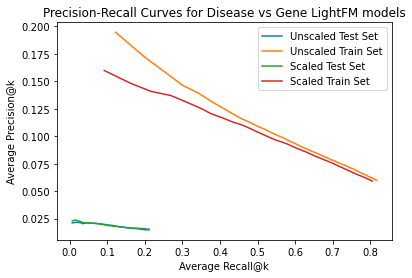

In [18]:
#Plot precision-recall curves for train and test data for both scaled and unscaled data
fig = plt.figure()
fig.patch.set_facecolor('white')
plt.plot(test_recall, test_precision)
plt.plot(train_recall, train_precision)
plt.plot(test_recall_scaled, test_precision_scaled)
plt.plot(train_recall_scaled, train_precision_scaled)
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Unscaled Test Set', 'Unscaled Train Set', 'Scaled Test Set', 'Scaled Train Set'])
plt.title('Precision-Recall Curves for Disease vs Gene LightFM models')
plt.savefig('PR_Curves_Disease_vs_Gene_LightFM_scaled_and_unscaled_data_CT20210927.jpeg')

In [72]:
r = model.predict_rank(data['test'])
print(r)

  (2, 5235)	90.0
  (4, 1520)	6118.0
  (5, 349)	120.0
  (5, 515)	344.0
  (5, 708)	0.0
  (5, 717)	162.0
  (5, 721)	140.0
  (5, 1112)	141.0
  (5, 1312)	270.0
  (5, 1622)	20.0
  (5, 1887)	4.0
  (5, 1900)	190.0
  (5, 1903)	15.0
  (5, 1972)	97.0
  (5, 2221)	263.0
  (5, 2289)	5270.0
  (5, 3137)	1418.0
  (5, 3304)	200.0
  (5, 3721)	274.0
  (5, 3724)	30.0
  (5, 3728)	174.0
  (5, 3828)	114.0
  (5, 5226)	108.0
  (5, 5356)	152.0
  (5, 5852)	154.0
  :	:
  (11066, 1170)	258.0
  (11072, 2455)	5635.0
  (11075, 622)	2797.0
  (11077, 3626)	9009.0
  (11082, 9117)	7959.0
  (11088, 2498)	6722.0
  (11100, 6950)	4357.0
  (11103, 2485)	6600.0
  (11105, 6318)	5508.0
  (11114, 7704)	6159.0
  (11126, 427)	3835.0
  (11141, 7588)	1034.0
  (11143, 3934)	1777.0
  (11145, 375)	125.0
  (11148, 1285)	4950.0
  (11154, 5000)	990.0
  (11158, 2299)	211.0
  (11167, 2367)	1018.0
  (11171, 2342)	633.0
  (11172, 3526)	4167.0
  (11173, 4541)	71.0
  (11173, 5244)	2089.0
  (11175, 543)	4589.0
  (11180, 295)	6911.0
  (11180, 2368)

In [71]:
def precision_at_k(
    model,
    test_interactions,
    train_interactions=None,
    k=10,
    user_features=None,
    item_features=None,
    preserve_rows=False,
    num_threads=1,
    check_intersections=True,
):
    """
    Measure the precision at k metric for a model: the fraction of known
    positives in the first k positions of the ranked list of results.
    A perfect score is 1.0.
    Parameters
    ----------
    model: LightFM instance
         the fitted model to be evaluated
    test_interactions: np.float32 csr_matrix of shape [n_users, n_items]
         Non-zero entries representing known positives in the evaluation set.
    train_interactions: np.float32 csr_matrix of shape [n_users, n_items], optional
         Non-zero entries representing known positives in the train set. These
         will be omitted from the score calculations to avoid re-recommending
         known positives.
    k: integer, optional
         The k parameter.
    user_features: np.float32 csr_matrix of shape [n_users, n_user_features], optional
         Each row contains that user's weights over features.
    item_features: np.float32 csr_matrix of shape [n_items, n_item_features], optional
         Each row contains that item's weights over features.
    preserve_rows: boolean, optional
         When False (default), the number of rows in the output will be equal
         to the number of users with interactions in the evaluation set.
         When True, the number of rows in the output will be equal to the
         number of users.
    num_threads: int, optional
         Number of parallel computation threads to use. Should
         not be higher than the number of physical cores.
    check_intersections: bool, optional, True by default,
        Only relevant when train_interactions are supplied.
        A flag that signals whether the test and train matrices should be checked
        for intersections to prevent optimistic ranks / wrong evaluation / bad data split.
    Returns
    -------
    np.array of shape [n_users with interactions or n_users,]
         Numpy array containing precision@k scores for each user. If there are
         no interactions for a given user the returned precision will be 0.
    """

    if num_threads < 1:
        raise ValueError("Number of threads must be 1 or larger.")
    
    print(test_interactions.todense()[2, 740])
    
    ranks = model.predict_rank(
        test_interactions,
        train_interactions=train_interactions,
        user_features=user_features,
        item_features=item_features,
        num_threads=num_threads,
        check_intersections=check_intersections,
    )
    print(np.squeeze(np.array(ranks.sum(axis=1))))
    print([i for i, dhs_pos in enumerate(list(ranks.data)) if dhs_pos == 1453])
    ranks.data = np.less(ranks.data, k, ranks.data)

    precision = np.squeeze(np.array(ranks.sum(axis=1))) / k

    if not preserve_rows:
        precision = precision[test_interactions.getnnz(axis=1) > 0]

    return precision
print(len(precision_at_k(model_scaled, data_scaled['test'], k=15)))
# print(data)

1.5
[   0.    0. 7003. ...    0.    0. 2139.]
[2553, 3783, 6339, 9371, 12457, 13088]
4453


In [69]:
print(data['test'].todense().shape)

(11181, 9703)


In [13]:
pickle_out_model = open('gd_model100.pickle', 'wb')
pickle.dump(model, pickle_out_model)
pickle_out_model.close()

pickle_out_data = open('gd_data100.pickle', 'wb')
pickle.dump(data, pickle_out_data)
pickle_out_data.close()

In [162]:
#function to recommend genes for a given disease. Takes in the model, data, and a list of
#diseases for genes to be recommend for. For each disease, prints out known associated genes
#and a list of recommended genes. Function modeled after tutorial 3, 'Recommendation Systems
#- Learn Python for Data Science' on LightFM github. 

def sample_recommendation(model, data, diseases, recommend_num=5, full_data=gd_coo):
    
    #number of diseases and genes in training dataset
    n_diseases, n_genes = data['train'].shape
    
    #generate gene recommendations for each disease
    for disease in diseases:
        disease_id = df[df['diseaseName'] == disease]['diseaseId'].tolist()[0]
        disease_id_num = list(diseaseId_values).index(disease_id)
        #genes known to relate to the disease
        known_positives = data['gene_ids'][data['train'].tocsr()[disease_id_num].indices]
#         known_positives = data['gene_ids'][np.argsort(-gd_coo.todense()[disease_id_num, :])]
        known_ranked = list(np.squeeze(np.asarray(np.argsort(-gd_coo.todense()[disease_id_num, :]))))
#         print(known_ranked)
        
        #genes model predicts that relate to disease
        scores = model.predict(disease_id_num, np.arange(n_genes))
#         print(np.argsort(-scores))
#         print(max(np.argsort(-scores)))
        #rank from most related to least
        top_genes = data['gene_ids'][np.argsort(-scores)]
        
        #print results
        print('Disease: ' + disease + ' (' + str(disease_id_num) +')')
        print('   Known Positives:')
        
        known_pos = []
        gd_dense = gd_coo.todense()
        for gene in known_ranked[:5]:
            association_score = gd_dense[disease_id_num, gene]
#             association_score = df[(df['geneId'] == gene) & (df['diseaseName']==disease)]['score'].tolist()[0]
            if association_score == 0:
                break
            geneId = data['gene_ids'][gene]
            x = df[df['geneId'] == geneId]['geneSymbol'].tolist()[0]
            known_pos.append(x)
            print('      %s (%s)' %(x, association_score))
        
        print()
        print('   Recommended:')
        count = 0
        for gene in top_genes[:]:
            x = df[df['geneId'] == gene]['geneSymbol'].tolist()[0]
            if x not in known_pos:
                print('      %s' % x)
                count += 1
            if count == recommend_num:
                break
                
        print()
            
sample_recommendation(model, data, ['Lung Neoplasms'])
sample_recommendation(model_scaled, data_scaled, ['Lung Neoplasms'], full_data=gd_scaled)

Disease: Lung Neoplasms (1030)
   Known Positives:
      CDKN2A (0.8)
      TP53 (0.8)
      PTEN (0.7)
      PIK3CA (0.6)
      GSTP1 (0.6)

   Recommended:
      CCND1
      HRAS
      PCNA
      GSTM1
      KRAS

Disease: Lung Neoplasms (1030)
   Known Positives:
      CDKN2A (0.8)
      TP53 (0.8)
      PTEN (0.7)
      PIK3CA (0.6)
      GSTP1 (0.6)

   Recommended:
      EGFR
      KDR
      SPP1
      CYP2A6
      APOA1



In [20]:
#Sanity checks below for above function
print(data['gene_ids'][data['train'].tocsr()[3].indices])

mask1 = gd_matrix[1]>0
mask2 = gd_matrix[196]>0
mask3 = gd_matrix[213]>0
# mask4 = gd_matrix[387]>0
print(gd_matrix[mask1 & mask2 & mask3])
print(df[df['diseaseId'] == 'C0019209'])

print(diseaseId_values[749])
i = list(diseaseId_values).index('C0019209')
print(i)

print(df[df['diseaseName'] == 'Hepatomegaly']['diseaseId'].tolist()[0])

disease = 'Mental Depression'
gene = 'IL6'
df[(df['geneSymbol'] == gene) & (df['diseaseName']==disease)]['score'].tolist()[0]

[ 387 2052]
